In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("../data/fish.csv")
df = pd.read_csv(DATA_PATH)

assert not df.empty
assert df.columns.is_unique
assert len(df) == len(df.drop_duplicates())

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(dropna=False),
})
quality

,dtype,missing,unique
Species,object,0,7
Weight,float64,0,101
Length1,float64,0,116
Length2,float64,0,93
Length3,float64,0,124
Height,float64,0,154
Width,float64,0,152


In [2]:
checks = pd.DataFrame({
    "check": [
        "Weight > 0",
        "Length1 > 0", "Length2 > 0", "Length3 > 0",
        "Height > 0", "Width > 0",
        "Length1 <= Length2", "Length2 <= Length3",
        "Species in known set",
    ],
    "violations": [
        (df["Weight"] <= 0).sum(),
        (df["Length1"] <= 0).sum(), (df["Length2"] <= 0).sum(), (df["Length3"] <= 0).sum(),
        (df["Height"] <= 0).sum(), (df["Width"] <= 0).sum(),
        (df["Length1"] > df["Length2"]).sum(),
        (df["Length2"] > df["Length3"]).sum(),
        (~df["Species"].isin(["Bream","Roach","Whitefish","Parkki","Perch","Pike","Smelt"])).sum(),
    ],
})
checks

,check,violations
0,Weight > 0,1
1,Length1 > 0,0
2,Length2 > 0,0
3,Length3 > 0,0
4,Height > 0,0
5,Width > 0,0
6,Length1 <= Length2,0
7,Length2 <= Length3,0
8,Species in known set,0


In [3]:
# Строка с нулевой массой
zero_weight = df[df["Weight"] <= 0]
print("Нулевая масса:")
print(zero_weight)

# Контекст: сравнение с другими Roach
roach = df[(df["Species"] == "Roach") & (df["Weight"] > 0)]
print("\nRoach, медиана массы:", roach["Weight"].median())
print("Roach, медиана Length3:", roach["Length3"].median())
print("Аномальная строка Length3:", zero_weight["Length3"].values[0])

Нулевая масса:
   Species  Weight  Length1  Length2  Length3  Height   Width
40   Roach     0.0     19.0     20.5     22.8  6.4752  3.3516

Roach, медиана массы: 150.0
Roach, медиана Length3: 25.0
Аномальная строка Length3: 22.8


In [4]:
num_cols = ["Weight", "Length1", "Length2", "Length3", "Height", "Width"]
dup_mask = df.duplicated(subset=num_cols, keep=False)
print("Строк, совпадающих по всем числовым полям:", dup_mask.sum())
df[dup_mask].sort_values(num_cols)

Строк, совпадающих по всем числовым полям: 0


,Species,Weight,Length1,Length2,Length3,Height,Width


In [5]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
%matplotlib inline

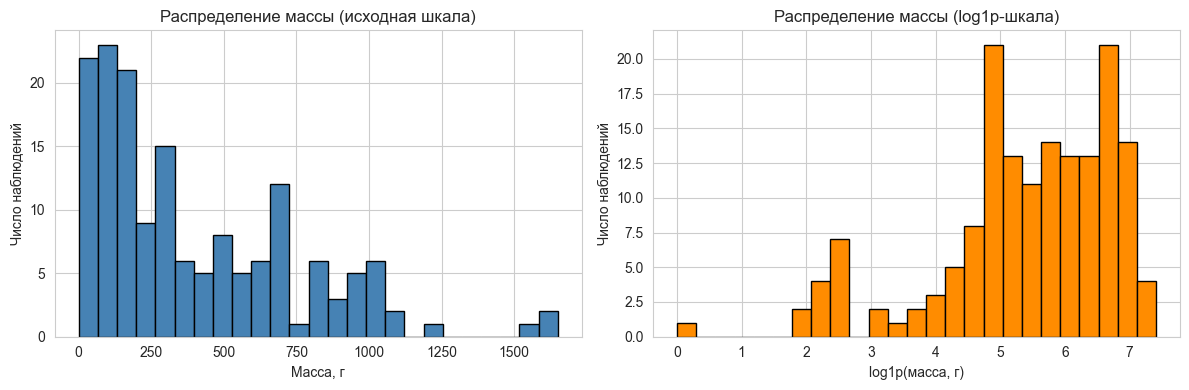

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Weight"], bins=25, color="steelblue", edgecolor="black")
axes[0].set_title("Распределение массы (исходная шкала)")
axes[0].set_xlabel("Масса, г")
axes[0].set_ylabel("Число наблюдений")

axes[1].hist(np.log1p(df["Weight"]), bins=25, color="darkorange", edgecolor="black")
axes[1].set_title("Распределение массы (log1p-шкала)")
axes[1].set_xlabel("log1p(масса, г)")
axes[1].set_ylabel("Число наблюдений")

plt.tight_layout()
plt.savefig("../reports/figures/01_weight_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

**Вывод.** Масса имеет сильную правостороннюю асимметрию (пик 0–250 г, хвост до 1650 г). Нулевое значение — не часть распределения, а закодированный пропуск. В log1p-шкале распределение приближается к симметричному, что снижает влияние выбросов и улучшает условия для линейных моделей.

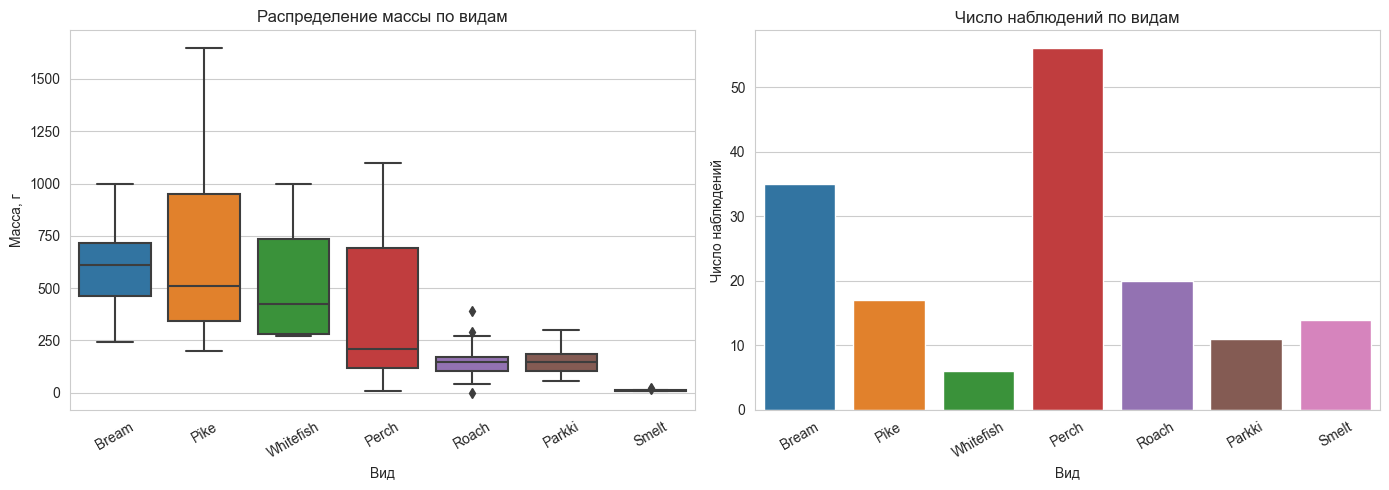

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = df.groupby("Species")["Weight"].median().sort_values(ascending=False).index

sns.boxplot(data=df, x="Species", y="Weight", order=order, ax=axes[0])
axes[0].set_title("Распределение массы по видам")
axes[0].set_xlabel("Вид")
axes[0].set_ylabel("Масса, г")
axes[0].tick_params(axis="x", rotation=30)

sns.countplot(data=df, x="Species", order=order, ax=axes[1])
axes[1].set_title("Число наблюдений по видам")
axes[1].set_xlabel("Вид")
axes[1].set_ylabel("Число наблюдений")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("../reports/figures/02_weight_by_species.png", dpi=120, bbox_inches="tight")
plt.show()

**Вывод.** Масса значимо различается по видам: Smelt и Roach — самые лёгкие (медианы ~50 и ~150 г), Whitefish и Bream — самые тяжёлые (медианы ~600 г). Наибольший разброс у Pike (от 200 до 1650 г), что делает вид сильным кандидатом на отдельный коэффициент в модели. Численность видов различается почти в 10 раз (Perch 56 против Whitefish 6) — требуется стратифицированное разбиение и осторожность при оценке метрик по малым группам.

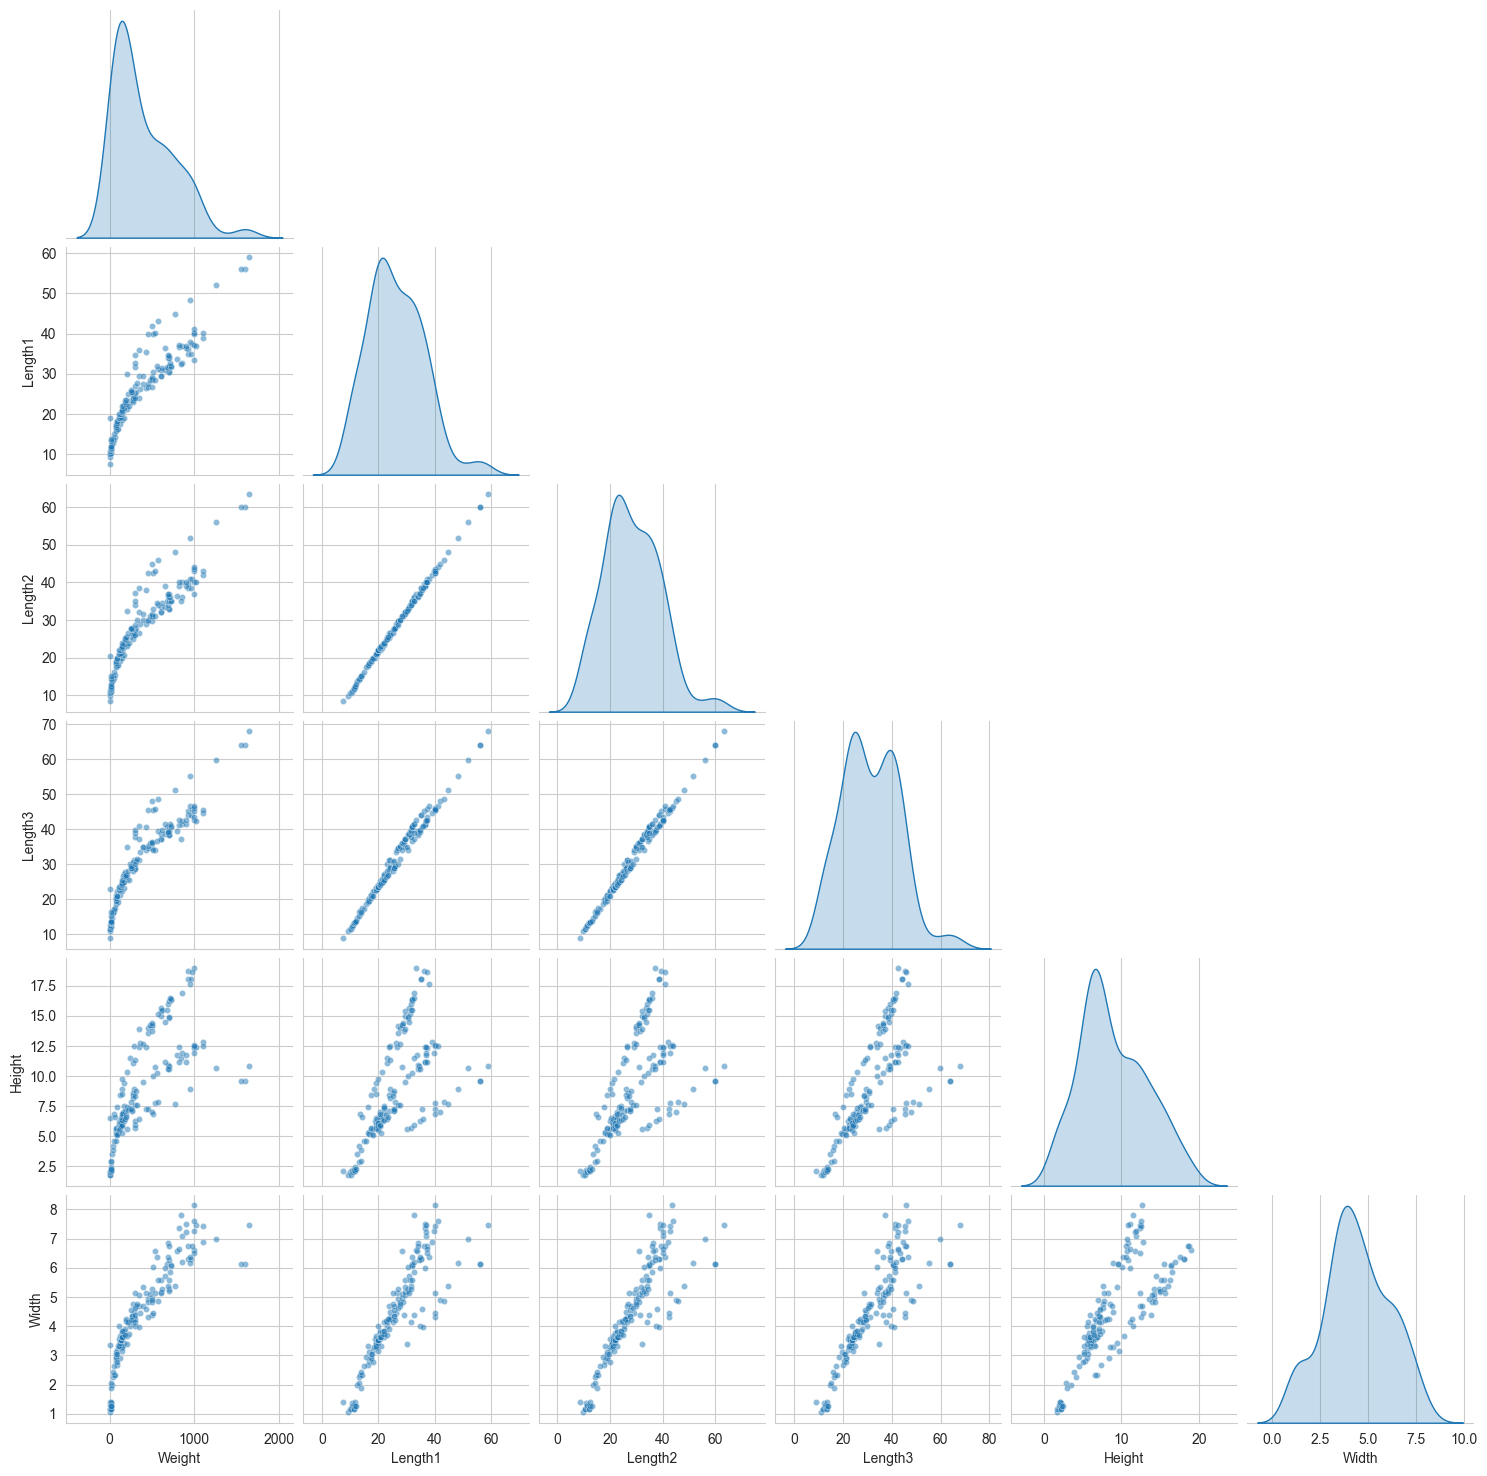

In [8]:
selected = ["Weight", "Length1", "Length2", "Length3", "Height", "Width"]
g = sns.pairplot(df[selected].dropna(), diag_kind="kde", corner=True, plot_kws={"alpha": 0.5, "s": 20})
g.savefig("../reports/figures/03_pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

**Вывод.** Три признака длины (Length1, Length2, Length3) попарно почти линейно зависимы — это три вложенных измерения одного объекта, что создаёт мультиколлинеарность при одновременном включении в линейную модель. Связь массы с длинами нелинейная (выпуклая, ближе к степенной W ~ L^3), поэтому одних длин в линейной регрессии недостаточно; логарифмирование или объёмный признак (L×H×W) предпочтительнее. Height и Width слабее связаны с массой и имеют отдельные структуры (двугорбость Height), требующие отдельной проверки.

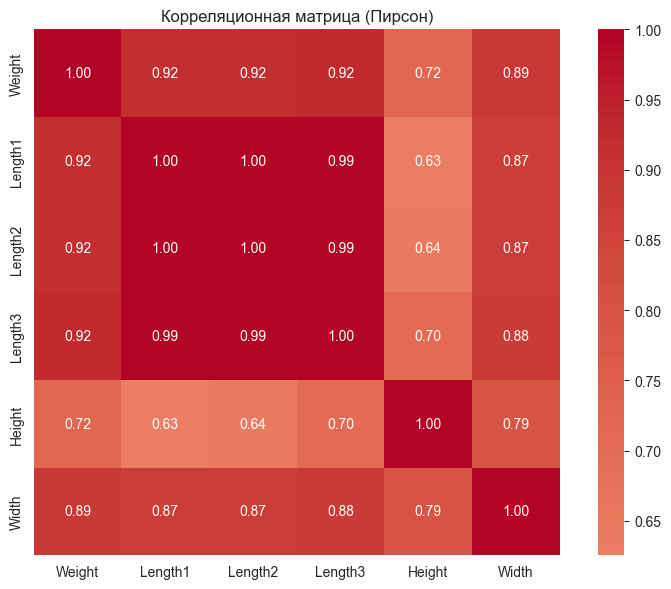

Weight     1.000000
Length3    0.923044
Length2    0.918618
Length1    0.915712
Width      0.886507
Height     0.724345
Name: Weight, dtype: float64

In [9]:
corr = df.drop(columns=["Species"]).corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Корреляционная матрица (Пирсон)")
plt.tight_layout()
plt.savefig("../reports/figures/04_correlation_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

corr["Weight"].sort_values(ascending=False)

**Вывод.** Корреляция Пирсона между тремя длинами 0.99–1.00 — они дублируют друг друга, включать все три в модель нельзя (мультиколлинеарность). С массой сильнее всего связаны Length3 (0.92), Length2 (0.92), Length1 (0.92) — практически одинаково. Width 0.89, Height 0.72. Корреляция Пирсона измеряет только линейную связь, а на pairplot связь массы с длинами выпуклая, поэтому реальная объяснительная сила признаков выше, чем r. Удалять признак автоматически по порогу 0.9 нельзя — это требует отдельного решения, а не механического отбрасывания.

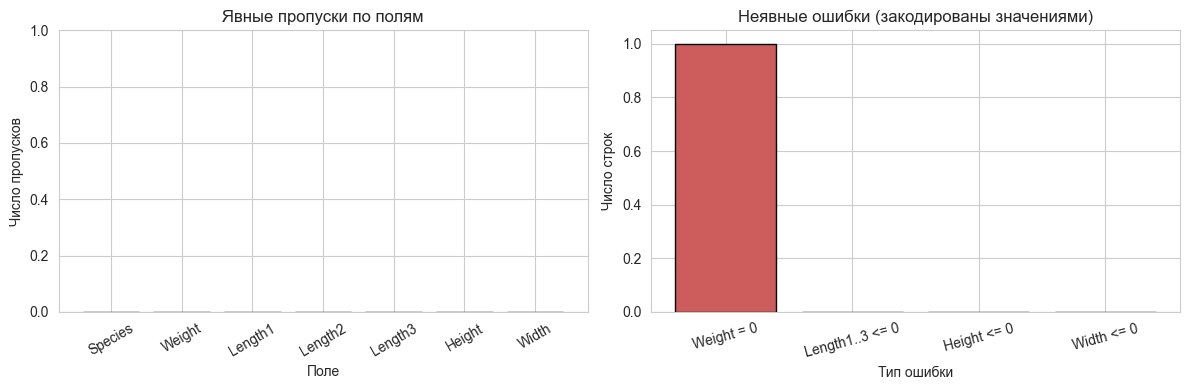

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

missing = df.isna().sum()
axes[0].bar(missing.index, missing.values, color="steelblue", edgecolor="black")
axes[0].set_title("Явные пропуски по полям")
axes[0].set_xlabel("Поле")
axes[0].set_ylabel("Число пропусков")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylim(0, 1)

implicit = pd.Series({
    "Weight = 0": (df["Weight"] == 0).sum(),
    "Length1..3 <= 0": ((df[["Length1","Length2","Length3"]] <= 0).any(axis=1)).sum(),
    "Height <= 0": (df["Height"] <= 0).sum(),
    "Width <= 0": (df["Width"] <= 0).sum(),
})
axes[1].bar(implicit.index, implicit.values, color="indianred", edgecolor="black")
axes[1].set_title("Неявные ошибки (закодированы значениями)")
axes[1].set_xlabel("Тип ошибки")
axes[1].set_ylabel("Число строк")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("../reports/figures/05_missing.png", dpi=120, bbox_inches="tight")
plt.show()

**Вывод.** Явных пропусков в таблице нет ни по одному полю. Единственная ошибка данных — масса, закодированная нулём (строка с индексом 40, вид Roach). Это MNAR-подобный случай: значение отсутствует, но не помечено как NA, а заменено невозможным числом. Явные пропуски и неявные ошибки требуют разных решений: первые можно обрабатывать типовыми методами (импутация, удаление), вторые сначала нужно обнаружить через проверку физического смысла.

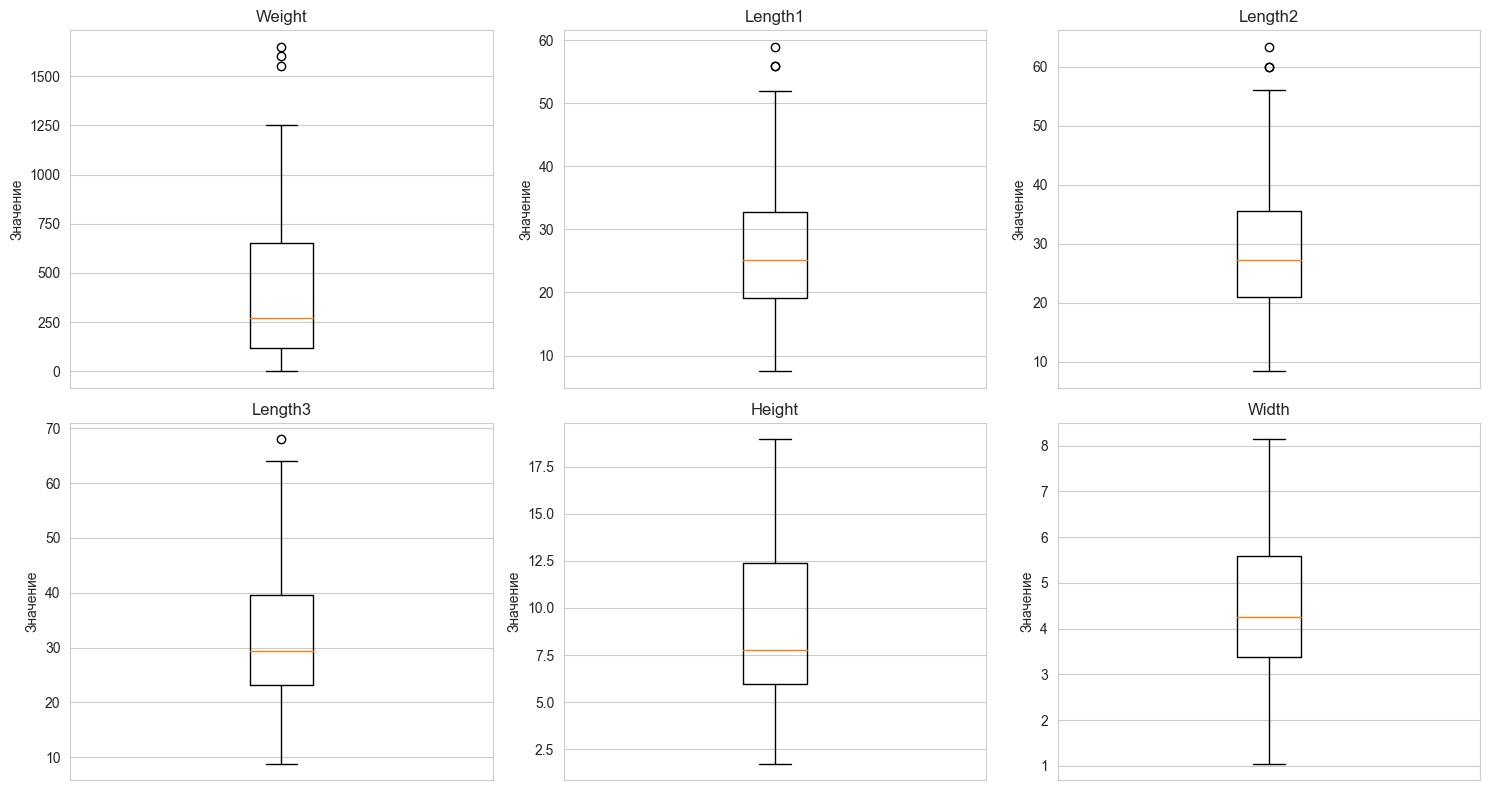

Число IQR-выбросов по признакам:
  Weight: 3
  Length1: 3
  Length2: 3
  Length3: 1
  Height: 0
  Width: 0


,Species,Weight,Length3,Height,Width
121,Perch,1015.0,42.4,12.3808,7.4624
123,Perch,1100.0,44.6,12.8002,6.8684
125,Perch,1100.0,45.5,12.5125,7.4165
141,Pike,1250.0,59.7,10.6863,6.9849
142,Pike,1600.0,64.0,9.6000,6.1440
143,Pike,1550.0,64.0,9.6000,6.1440
144,Pike,1650.0,68.0,10.8120,7.4800


In [11]:
num_feats = ["Weight", "Length1", "Length2", "Length3", "Height", "Width"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for i, col in enumerate(num_feats):
    axes[i].boxplot(df[col].dropna(), vert=True)
    axes[i].set_title(col)
    axes[i].set_ylabel("Значение")
    axes[i].set_xticks([])

plt.tight_layout()
plt.savefig("../reports/figures/06_outliers.png", dpi=120, bbox_inches="tight")
plt.show()

# Строки, попадающие в IQR-выбросы по каждому признаку
out_rows = {}
for col in num_feats:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    out = df[(df[col] < lo) | (df[col] > hi)]
    out_rows[col] = len(out)

print("Число IQR-выбросов по признакам:")
for k, v in out_rows.items():
    print(f"  {k}: {v}")

df[df["Weight"] > 1000][["Species", "Weight", "Length3", "Height", "Width"]]

**Вывод.** По IQR-критерию подозрительны 3 строки по массе, 3 по Length1, 3 по Length2, 1 по Length3; по Height и Width — ноль. Все «выбросы» — крупные экземпляры Pike и Perch с массой 1000–1650 г и длиной 42–68 см. Это не ошибки измерения, а реальные наблюдения, наиболее ценные для проверки обобщающей способности модели. Автоматическое удаление таких строк лишит модель информации о крайних значениях и исказит диапазон применимости. Решение: оставить, возможно добавить флаг is_large.

In [12]:
def mad_outliers(series, threshold=3.5):
    med = series.median()
    mad = (series - med).abs().median()
    if mad == 0:
        return pd.Series(False, index=series.index)
    z = 0.6745 * (series - med) / mad
    return z.abs() > threshold

mad_rows = {}
iqr_rows = {}

for col in num_feats:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    iqr_mask = (df[col] < lo) | (df[col] > hi)
    mad_mask = mad_outliers(df[col])

    iqr_rows[col] = set(df.index[iqr_mask].tolist())
    mad_rows[col] = set(df.index[mad_mask].tolist())

    print(f"{col}: IQR={len(iqr_rows[col])}, MAD={len(mad_rows[col])}, "
          f"пересечение={len(iqr_rows[col] & mad_rows[col])}, "
          f"только IQR={sorted(iqr_rows[col] - mad_rows[col])}, "
          f"только MAD={sorted(mad_rows[col] - iqr_rows[col])}")

Weight: IQR=3, MAD=3, пересечение=3, только IQR=[], только MAD=[]
Length1: IQR=3, MAD=0, пересечение=0, только IQR=[142, 143, 144], только MAD=[]
Length2: IQR=3, MAD=0, пересечение=0, только IQR=[142, 143, 144], только MAD=[]
Length3: IQR=1, MAD=0, пересечение=0, только IQR=[144], только MAD=[]
Height: IQR=0, MAD=0, пересечение=0, только IQR=[], только MAD=[]
Width: IQR=0, MAD=0, пересечение=0, только IQR=[], только MAD=[]


**Вывод.** IQR и MAD дают разный результат для признаков длины: по Weight методы согласны (3 общих выброса), по Length1/Length2 IQR отмечает строки 142, 143, 144, а MAD — ни одной, по Length3 IQR — 144, MAD — ноль. Причина в форме распределения: у длин плотное ядро и длинный тяжёлый хвост, поэтому MAD (на медиане) консервативнее IQR (на квартилях). Расхождение методов — аргумент против автоматического удаления: строки 142–144 — крупные Pike, крайние значения по длине, но не ошибки измерения. Решение: оставить. Критерий выброса не равен критерию ошибки.

In [13]:
df["Volume"] = df["Length3"] * df["Height"] * df["Width"]

corr_vol = df[["Weight", "Volume", "Length3", "Height", "Width"]].corr()["Weight"].sort_values(ascending=False)
print("Корреляции с Weight:")
print(corr_vol)

# Отдельно по видам — насколько стабильна связь
by_species = df.groupby("Species").apply(lambda g: g["Weight"].corr(g["Volume"]))
print("\nКорреляция Weight ~ Volume по видам:")
print(by_species.sort_values(ascending=False))

Корреляции с Weight:
Weight     1.000000
Volume     0.932355
Length3    0.923044
Width      0.886507
Height     0.724345
Name: Weight, dtype: float64

Корреляция Weight ~ Volume по видам:
Species
Parkki       0.995595
Perch        0.992972
Whitefish    0.986034
Smelt        0.973153
Bream        0.961709
Pike         0.958935
Roach        0.945149
dtype: float64


**Вывод.** Корреляция Weight ~ Volume в целом по таблице 0.932, что лишь немного выше одиночной Length3 (0.923). Однако внутри видов корреляция радикально выше: от 0.945 (Roach) до 0.996 (Parkki). Разрыв между общей и внутривидовой корреляцией — это эффект смешения (Simpson's paradox-like): разные виды имеют разную плотность и форму тела, поэтому при одинаковом объёме масса отличается. Следовательно, Volume сам по себе не заменяет вид как признак. Гипотеза 1 подтверждается с оговоркой: объём полезен, но сильнее всего работает в комбинации со Species.

In [14]:
roach = df[(df["Species"] == "Roach") & (df["Weight"] > 0)]
print("Roach без нуля:", roach["Weight"].corr(roach["Volume"]).round(4))

roach_all = df[df["Species"] == "Roach"]
print("Roach с нулём:", roach_all["Weight"].corr(roach_all["Volume"]).round(4))

# То же для общей картины
df_clean = df[df["Weight"] > 0]
print("\nОбщая корреляция с нулём:  ", df["Weight"].corr(df["Volume"]).round(4))
print("Общая корреляция без нуля:", df_clean["Weight"].corr(df_clean["Volume"]).round(4))

Roach без нуля: 0.9907
Roach с нулём: 0.9451

Общая корреляция с нулём:   0.9324
Общая корреляция без нуля: 0.9323


**Вывод.** Одна строка с массой 0 (индекс 40, Roach) снижает внутривидовую корреляцию Weight ~ Volume с 0.9907 до 0.9451 — почти на 0.05. На общую корреляцию по всей таблице эта же строка почти не влияет (0.9323 против 0.9324), потому что тонет в 159 наблюдениях. Это типичный эффект MNAR-ошибки в малочисленной группе: одна некорректная запись сильно искажает групповые оценки и почти незаметна на общих. Практический вывод: строка 40 — единственный кандидат на удаление из обучения массе. В EDA оставляем, чтобы показать причину.

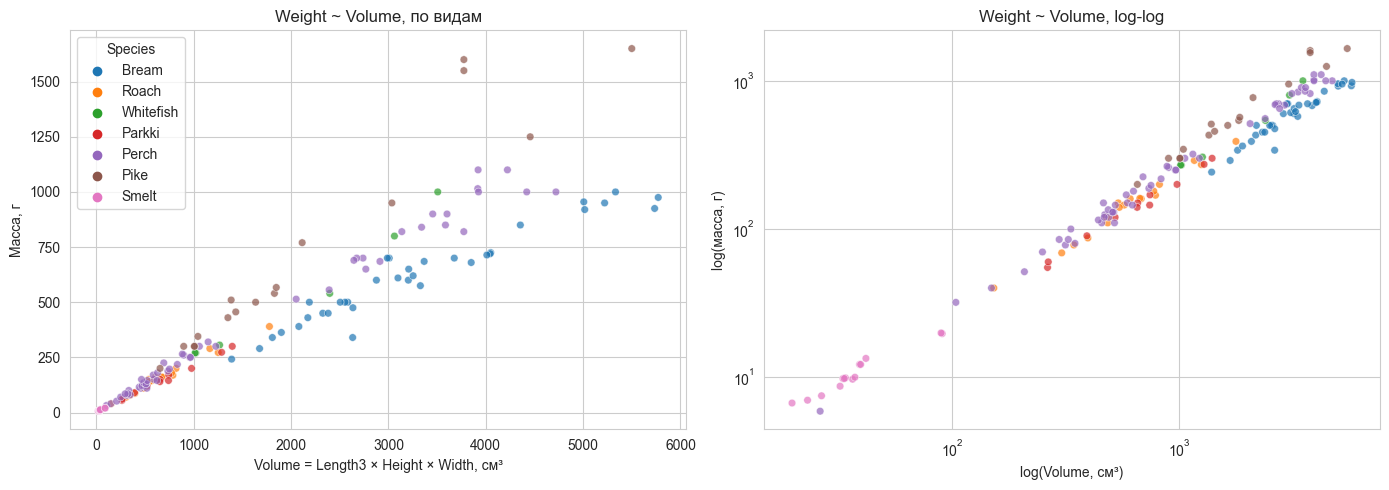

In [15]:
plot_df = df[df["Weight"] > 0].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=plot_df, x="Volume", y="Weight", hue="Species", ax=axes[0], s=30, alpha=0.7)
axes[0].set_title("Weight ~ Volume, по видам")
axes[0].set_xlabel("Volume = Length3 × Height × Width, см³")
axes[0].set_ylabel("Масса, г")

sns.scatterplot(data=plot_df, x="Volume", y="Weight", hue="Species", ax=axes[1], s=30, alpha=0.7, legend=False)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Weight ~ Volume, log-log")
axes[1].set_xlabel("log(Volume, см³)")
axes[1].set_ylabel("log(масса, г)")

plt.tight_layout()
plt.savefig("../reports/figures/07_hypothesis_volume.png", dpi=120, bbox_inches="tight")
plt.show()

**Вывод.** На линейной шкале точки разных видов лежат с систематическим сдвигом: при одинаковом объёме Pike тяжелее, Bream легче. На log-log шкале все точки выстраиваются в прямую линию с малым разбросом, что подтверждает степенную зависимость W ~ V^α. Однако сдвиг между видами меньше общего разброса вдоль линии — эффект Species значим, но по силе уступает объёму. Гипотеза 1 (объём как главный предиктор) подтверждается; гипотеза 2 (вид как независимый фактор) подтверждается с оговоркой — вклад вида есть, но второго порядка.

In [16]:
# Гипотеза 2: вид добавляет объяснительную силу сверх геометрии
import statsmodels.formula.api as smf

m1 = smf.ols("Weight ~ Volume", data=df_clean).fit()
m2 = smf.ols("Weight ~ Volume + C(Species)", data=df_clean).fit()

print("Без Species:   R² =", round(m1.rsquared, 4), " Adj R² =", round(m1.rsquared_adj, 4))
print("Со Species:    R² =", round(m2.rsquared, 4), " Adj R² =", round(m2.rsquared_adj, 4))

# Проверка значимости вклада Species через F-тест
from statsmodels.stats.anova import anova_lm
print("\nANOVA:")
print(anova_lm(m1, m2))

Без Species:   R² = 0.8691  Adj R² = 0.8683
Со Species:    R² = 0.9468  Adj R² = 0.9443

ANOVA:
   df_resid           ssr  df_diff       ss_diff          F        Pr(>F)
0     156.0  2.628520e+06      0.0           NaN        NaN           NaN
1     150.0  1.069050e+06      6.0  1.559470e+06  36.468589  5.213706e-27


**Вывод.** Добавление Species к модели Weight ~ Volume повышает R² с 0.869 до 0.947 и Adj R² с 0.868 до 0.944. ANOVA даёт F = 36.47, p = 5.2e-27 — вклад вида статистически высокозначим. Гипотеза 2 подтверждена: вид несёт независимую объяснительную силу сверх геометрии. При этом модель с двумя признаками (Volume + Species, Adj R² 0.944) не намного уступает модели автора из шести признаков (Adj R² 0.960), что говорит о сильной избыточности трёх длин и вторичности Height/Width.

**Правило разбиения.** Единица наблюдения — отдельная рыба. Групп (партий, ферм, моментов времени) в данных нет, поэтому стратификация по Species, а не group split. Строка с Weight = 0 исключается до разбиения. Пропорции 60/20/20, stratify=Species, random_state фиксирован для воспроизводимости.

In [17]:
from sklearn.model_selection import train_test_split

df_model = df[df["Weight"] > 0].copy()

train_val, test = train_test_split(
    df_model, test_size=0.2, stratify=df_model["Species"], random_state=42
)
train, val = train_test_split(
    train_val, test_size=0.25, stratify=train_val["Species"], random_state=42
)

print("train:", train.shape, " val:", val.shape, " test:", test.shape)
print("\nРаспределение видов в train:")
print(train["Species"].value_counts())
print("\nРаспределение видов в val:")
print(val["Species"].value_counts())
print("\nРаспределение видов в test:")
print(test["Species"].value_counts())

train: (94, 8)  val: (32, 8)  test: (32, 8)

Распределение видов в train:
Perch        33
Bream        21
Roach        11
Pike         10
Smelt         8
Parkki        7
Whitefish     4
Name: Species, dtype: int64

Распределение видов в val:
Perch        12
Bream         7
Roach         4
Pike          3
Smelt         3
Parkki        2
Whitefish     1
Name: Species, dtype: int64

Распределение видов в test:
Perch        11
Bream         7
Roach         4
Pike          4
Smelt         3
Parkki        2
Whitefish     1
Name: Species, dtype: int64


**Возможные каналы утечки:**

| # | Канал | Где может возникнуть | Меры |
|---|-------|----------------------|------|
| 1 | Статистики всей таблицы | Стандартизация, импутация, подбор гиперпараметров по всей таблице до разбиения | Считать mean/std/quantile только на train, применять к val/test |
| 2 | Повторные строки | Одна и та же рыба занесена дважды; при случайном разбиении попадёт и в train, и в test | Проверка дубликатов до разбиения (в наших данных — 0) |
| 3 | Идентификатор | Использование индекса строки как признака | Индекс не подавать в модель; столбца id в датасете нет |
| 4 | Постфактум измерение | Случайное измерение, доступное только после взвешивания (например, фактическая масса) | Признак Volume вычисляется только из L/H/W, целевая переменная не используется |
| 5 | Ручной подбор по тесту | Итеративная подгонка модели и признаков с оглядкой на test | Test трогаем один раз, в самом конце; вся настройка — на val |